# 15 Fashion-MNIST MLP：TT-rank × 更新方式の統合trade-off

Notebook 13のrank 16／32／64と、Notebook 14のrank 12を同じ表・図へ統合します。新しい学習やtest評価は行いません。

このNotebookで答える問いは、次のとおりです。

> rank・更新方式を変えたとき、モデルサイズ、分類性能、denseへの近さ、学習コストの間にどのようなtrade-offがあるか。

今回は新しいTT実装を学ぶ段階ではないため、形式的なTODOは置かず、保存済み結果の検証と統合を完成コードで行います。

## 1. 統合と候補整理の規則

分類用途の暫定候補は、既存の許容差`ACCURACY_TOLERANCE = 0.001`を用いて整理します。これは13・14の実験前に事前登録した最終選択規則ではありません。既存の許容差を保存済み候補へ同じように適用し、今回の結果に合わせて変更しないという位置付けです。

$$
\mathrm{accuracy}_{\mathrm{candidate}} \geq \mathrm{accuracy}_{\mathrm{dense}} - \mathrm{ACCURACY\_TOLERANCE}
$$

このcutoffは統計的な信頼区間や理論的な誤差限界ではなく、保存済み候補を同じ基準で整理するための許容下限です。条件を満たす候補のうち、モデル総parameter数が最小の候補をすべて残します。同率なら暗黙に`tt_cores_only`を優先しません。

Pareto frontierでは、横軸のモデル総parameter数を最小化し、縦軸は図ごとに`1 - accuracy`、`1 - prediction agreement`、logits RMSEを最小化します。trainable parameter数や学習時間は、この3種類のPareto判定には使いません。accuracy、prediction agreement、logits RMSEは意味が異なるため、それぞれ別に整理します。kneeは補助情報であり、上のaccuracy tolerance規則による候補選択とは別です。

In [21]:
# importとプロジェクトルートの解決
import ast
import json
import re
import sys
from collections.abc import Mapping, Sequence
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.axes import Axes

for candidate in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    src_dir = candidate / "src"
    if (src_dir / "nn_compression").is_dir():
        if str(src_dir) not in sys.path:
            sys.path.insert(0, str(src_dir))
        break
else:
    raise RuntimeError("src/nn_compression が見つかりません。")

from nn_compression.selection import (
    extract_pareto_frontier,
    find_knee_point,
    get_endpoints,
    line_equation,
)
from nn_compression.utils import find_project_root, get_experiment_dirs

In [22]:
# 入力とNotebook 15専用の出力先
ACCURACY_TOLERANCE = 0.001
SAVE_RESULTS = True

project_root = find_project_root(Path.cwd())
_, _, results_dir = get_experiment_dirs(
    project_root,
    "30_tt_mps",
    "10_fashion_mnist_mlp",
    "15_integrated_tt_rank_update_scope_tradeoff",
    create=False,
)
notebook_dir = (
    project_root / "notebooks" / "30_tt_mps"
    / "10_fashion_mnist_mlp"
)
results_base = (
    project_root / "results" / "30_tt_mps"
    / "10_fashion_mnist_mlp"
)
models_base = (
    project_root / "models" / "30_tt_mps"
    / "10_fashion_mnist_mlp"
)

notebook13_path = notebook_dir / "13_tt_cores_only_ablation.ipynb"
notebook14_path = notebook_dir / "14_rank12_update_scope_ablation.ipynb"
results13_dir = results_base / "13_tt_cores_only_ablation"
results14_dir = results_base / "14_rank12_update_scope_ablation"
models13_dir = models_base / "13_tt_cores_only_ablation"
models14_dir = models_base / "14_rank12_update_scope_ablation"
comparison13_path = results13_dir / "update_scope_comparison.csv"
history13_path = results13_dir / "update_scope_history.csv"
comparison14_path = results14_dir / "rank12_comparison.csv"
epoch0_14_path = results14_dir / "rank12_epoch0.csv"
history14_path = results14_dir / "rank12_history.csv"

required_paths = [
    notebook13_path, notebook14_path,
    comparison13_path, history13_path, comparison14_path,
    epoch0_14_path, history14_path,
]
for required_path in required_paths:
    if not required_path.is_file():
        raise FileNotFoundError(f"必要な入力がありません: {required_path}")

print("results target:", results_dir)

results target: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\15_integrated_tt_rank_update_scope_tradeoff


## 2. Notebook 13・14の比較条件を確認する

結果を結合する前に、Notebook 13・14のコードから共通条件を読み取ります。性能・時間は13・14のCSV、比較条件とdense基準値は13・14のNotebook、rank 64の同一性は保存済みcheckpointを根拠にします。保存済み数値が似ているだけでは、同じ比較条件だったとは判断しません。

In [23]:
def load_code_trees(notebook_path: Path) -> tuple[list[ast.AST], str]:
    """Notebookの全code cellをASTと連結sourceとして読み込む。"""
    notebook = json.loads(notebook_path.read_text(encoding="utf-8"))
    sources = [
        "".join(cell.get("source", []))
        for cell in notebook["cells"]
        if cell.get("cell_type") == "code"
    ]
    return [ast.parse(source) for source in sources], "\n".join(sources)


def extract_literal_assignments(
    trees: Sequence[ast.AST],
    variable_names: Sequence[str],
) -> dict[str, Any]:
    """ASTから`ast.literal_eval`可能な単純代入を取得する。"""
    requested = set(variable_names)
    found: dict[str, Any] = {}
    for tree in trees:
        for node in ast.walk(tree):
            if not isinstance(node, ast.Assign) or len(node.targets) != 1:
                continue
            target = node.targets[0]
            if not isinstance(target, ast.Name) or target.id not in requested:
                continue
            try:
                found[target.id] = ast.literal_eval(node.value)
            except (ValueError, TypeError):
                continue
    return found


def assignment_fingerprint(trees: Sequence[ast.AST], name: str) -> str:
    """指定した代入右辺を、位置情報を除いたAST文字列で返す。"""
    matches = []
    for tree in trees:
        for node in ast.walk(tree):
            if not isinstance(node, ast.Assign):
                continue
            if any(isinstance(target, ast.Name) and target.id == name for target in node.targets):
                matches.append(ast.dump(node.value, include_attributes=False))
    if len(matches) != 1:
        raise ValueError(f"{name}の単一代入を確認できません: {len(matches)}件")
    return matches[0]


def call_fingerprints(
    trees: Sequence[ast.AST],
    qualified_name: str,
) -> list[str]:
    """指定した関数呼び出しを、位置情報を除いたAST文字列で返す。"""
    matches = []
    for tree in trees:
        for node in ast.walk(tree):
            if isinstance(node, ast.Call) and ast.unparse(node.func) == qualified_name:
                matches.append(ast.dump(node, include_attributes=False))
    return matches


trees13, source13 = load_code_trees(notebook13_path)
trees14, source14 = load_code_trees(notebook14_path)

common_config_names = [
    "SEED", "TARGET_LAYER", "TRAIN_BATCH_SIZE",
    "VALIDATION_BATCH_SIZE", "LEARNING_RATE",
    "MAX_EPOCHS", "PATIENCE", "MIN_DELTA",
]
config13 = extract_literal_assignments(trees13, common_config_names)
config14 = extract_literal_assignments(trees14, common_config_names)

if set(config13) != set(common_config_names):
    raise ValueError(f"Notebook 13の設定を取得できません: {config13}")
if set(config14) != set(common_config_names):
    raise ValueError(f"Notebook 14の設定を取得できません: {config14}")

provenance_records = []
for variable_name in common_config_names:
    value13 = config13[variable_name]
    value14 = config14[variable_name]
    provenance_records.append({
        "setting": variable_name,
        "notebook13_value": value13,
        "notebook14_value": value14,
        "exact_match": value13 == value14,
        "verification": "literal assignment",
    })

structural_checks = [
    (
        "DTYPE", "torch.float32",
        assignment_fingerprint(trees13, "DTYPE")
        == assignment_fingerprint(trees14, "DTYPE"),
    ),
    (
        "BASELINE_CHECKPOINT", "baseline_same_run.pt",
        assignment_fingerprint(trees13, "baseline_checkpoint_path")
        == assignment_fingerprint(trees14, "baseline_checkpoint_path"),
    ),
    (
        "TENSORIZATION", "reversed_sites; same selected_tensorizations.csv",
        assignment_fingerprint(trees13, "selection_path")
        == assignment_fingerprint(trees14, "selection_path")
        and "reversed_sites" in source13
        and "reversed_sites" in source14,
    ),
    (
        "DATA_SPLIT", "50000/5000/5000; seed=SEED",
        len(call_fingerprints(trees13, "split_fashion_mnist_dataset")) == 1
        and call_fingerprints(trees13, "split_fashion_mnist_dataset")
        == call_fingerprints(trees14, "split_fashion_mnist_dataset"),
    ),
    (
        "OPTIMIZER", "torch.optim.Adam; lr=LEARNING_RATE",
        len(call_fingerprints(trees13, "torch.optim.Adam")) == 1
        and call_fingerprints(trees13, "torch.optim.Adam")
        == call_fingerprints(trees14, "torch.optim.Adam"),
    ),
    (
        "LOSS", "torch.nn.CrossEntropyLoss",
        len(call_fingerprints(trees13, "torch.nn.CrossEntropyLoss")) == 1
        and call_fingerprints(trees13, "torch.nn.CrossEntropyLoss")
        == call_fingerprints(trees14, "torch.nn.CrossEntropyLoss"),
    ),
]
for setting, value, exact_match in structural_checks:
    provenance_records.append({
        "setting": setting,
        "notebook13_value": value,
        "notebook14_value": value,
        "exact_match": exact_match,
        "verification": "AST/code evidence",
    })

df_integration_provenance = pd.DataFrame(provenance_records)
assert df_integration_provenance["exact_match"].all()
display(df_integration_provenance)

,setting,notebook13_value,notebook14_value,exact_match,verification
0,SEED,0,0,True,literal assignment
1,TARGET_LAYER,fc1,fc1,True,literal assignment
2,TRAIN_BATCH_SIZE,64,64,True,literal assignment
3,VALIDATION_BATCH_SIZE,64,64,True,literal assignment
4,LEARNING_RATE,0.001,0.001,True,literal assignment
5,MAX_EPOCHS,50,50,True,literal assignment
6,PATIENCE,5,5,True,literal assignment
7,MIN_DELTA,0.0001,0.0001,True,literal assignment
8,DTYPE,torch.float32,torch.float32,True,AST/code evidence
9,BASELINE_CHECKPOINT,baseline_same_run.pt,baseline_same_run.pt,True,AST/code evidence


## 3. 13・14のtrial結果とepoch 0を共通schemaへ統合する

モデル総parameter数は推論モデルの大きさ、trainable parameter数はfine-tuning時の更新範囲を表します。同rankの2方式では前者は同じですが、後者は異なります。

`cumulative_training_seconds`は各Notebookで計測した学習処理の累積値です。評価や描画を含む総wall-clock時間とはみなしません。

In [24]:
df_comparison13 = pd.read_csv(comparison13_path)
df_history13 = pd.read_csv(history13_path)
df_comparison14 = pd.read_csv(comparison14_path)
df_epoch0_14 = pd.read_csv(epoch0_14_path)
df_history14 = pd.read_csv(history14_path)


def extract_saved_dense_accuracy(notebook_path: Path) -> float:
    """保存済みstdoutからdense rank-validation accuracyを取得する。"""
    notebook = json.loads(notebook_path.read_text(encoding="utf-8"))
    pattern = re.compile(
        r"dense rank-validation: loss=[0-9.]+, accuracy=([0-9.]+)"
    )
    matches = []
    for cell in notebook["cells"]:
        for output in cell.get("outputs", []):
            if output.get("output_type") != "stream":
                continue
            text = output.get("text", "")
            if isinstance(text, list):
                text = "".join(text)
            matches.extend(float(value) for value in pattern.findall(text))
    unique_values = sorted(set(matches))
    if len(unique_values) != 1:
        raise ValueError(
            f"dense accuracyを一意に取得できません: {notebook_path}, "
            f"values={unique_values}"
        )
    return unique_values[0]


dense_accuracy13 = extract_saved_dense_accuracy(notebook13_path)
dense_accuracy14 = extract_saved_dense_accuracy(notebook14_path)
assert dense_accuracy13 == dense_accuracy14
dense_rank_validation_accuracy = dense_accuracy13
accuracy_cutoff = dense_rank_validation_accuracy - ACCURACY_TOLERANCE
df_dense_baseline_reference = pd.DataFrame([
    {
        "source": "Notebook 13 saved stdout",
        "rank_validation_accuracy": dense_accuracy13,
    },
    {
        "source": "Notebook 14 saved stdout",
        "rank_validation_accuracy": dense_accuracy14,
    },
])

# Notebook 13は実行epoch数をhistoryの最大epochから求める。
epochs13 = (
    df_history13.groupby(
        ["requested_rank", "update_scope"], as_index=False
    )["epoch"]
    .max()
    .rename(columns={"epoch": "num_epochs_run"})
)
trials13 = df_comparison13.merge(
    epochs13, on=["requested_rank", "update_scope"],
    validate="one_to_one",
)
trials13["source_notebook"] = 13

trials14 = df_comparison14.copy()
trials14["source_notebook"] = 14

trial_columns = [
    "source_notebook", "requested_rank", "update_scope",
    "selected_epoch", "rank_validation_accuracy",
    "prediction_agreement", "logits_rmse",
    "model_parameters", "model_compression_ratio",
    "trainable_parameters", "cumulative_training_seconds",
    "num_epochs_run",
]
df_integrated_trials = (
    pd.concat([trials13[trial_columns], trials14[trial_columns]])
    .sort_values(["requested_rank", "update_scope"])
    .reset_index(drop=True)
)
df_integrated_trials["training_seconds_per_epoch"] = (
    df_integrated_trials["cumulative_training_seconds"]
    / df_integrated_trials["num_epochs_run"]
)

# 13のepoch 0はhistoryから、14は専用CSVから取得する。
epoch0_13 = df_history13.loc[df_history13["epoch"] == 0].merge(
    df_comparison13[[
        "requested_rank", "update_scope", "model_parameters",
        "model_compression_ratio", "trainable_parameters",
    ]],
    on=["requested_rank", "update_scope"],
    validate="one_to_one",
)
epoch0_13["source_notebook"] = 13
epoch0_14 = df_epoch0_14.copy()
epoch0_14["source_notebook"] = 14

epoch0_columns = [
    "source_notebook", "requested_rank", "update_scope",
    "model_parameters", "model_compression_ratio",
    "trainable_parameters", "rank_validation_accuracy",
    "prediction_agreement", "logits_rmse",
]
df_integrated_epoch0 = (
    pd.concat([epoch0_13[epoch0_columns], epoch0_14[epoch0_columns]])
    .sort_values(["requested_rank", "update_scope"])
    .reset_index(drop=True)
)

assert len(df_integrated_trials) == 8
assert len(df_integrated_epoch0) == 8
assert set(df_integrated_trials["requested_rank"]) == {12, 16, 32, 64}
assert not df_integrated_trials[["requested_rank", "update_scope"]].duplicated().any()
assert (df_integrated_trials["num_epochs_run"] > 0).all()
assert np.isfinite(df_integrated_trials["training_seconds_per_epoch"]).all()

# 同rankの2方式が、CSV上でも同じepoch 0を表すことを確認する。
epoch0_shared_columns = [
    "model_parameters", "model_compression_ratio",
    "rank_validation_accuracy", "prediction_agreement",
    "logits_rmse",
]
epoch0_verification_records = []
for rank, frame in df_integrated_epoch0.groupby("requested_rank"):
    assert len(frame) == 2
    assert set(frame["update_scope"]) == {
        "all_parameters", "tt_cores_only",
    }
    all_row = frame.loc[frame["update_scope"] == "all_parameters"].iloc[0]
    cores_row = frame.loc[frame["update_scope"] == "tt_cores_only"].iloc[0]
    record = {"requested_rank": int(rank)}
    for column in epoch0_shared_columns:
        exact_match = all_row[column] == cores_row[column]
        record[f"{column}_exact_match"] = bool(exact_match)
        assert exact_match, f"epoch 0 mismatch: rank={rank}, column={column}"
    epoch0_verification_records.append(record)
df_epoch0_pair_verification = pd.DataFrame(epoch0_verification_records)

display(df_dense_baseline_reference)
display(df_epoch0_pair_verification)
display(df_integrated_trials.round(6))

,source,rank_validation_accuracy
0,Notebook 13 saved stdout,0.8884
1,Notebook 14 saved stdout,0.8884


,requested_rank,model_parameters_exact_match,model_compression_ratio_exact_match,rank_validation_accuracy_exact_match,prediction_agreement_exact_match,logits_rmse_exact_match
0,12,True,True,True,True,True
1,16,True,True,True,True,True
2,32,True,True,True,True,True
3,64,True,True,True,True,True


,source_notebook,requested_rank,update_scope,selected_epoch,rank_validation_accuracy,prediction_agreement,logits_rmse,model_parameters,model_compression_ratio,trainable_parameters,cumulative_training_seconds,num_epochs_run,training_seconds_per_epoch
0,14,12,all_parameters,7,0.8848,0.9304,4.400143,145570,3.680827,145570,43.254342,12,3.604528
1,14,12,tt_cores_only,17,0.8884,0.9280,5.097318,145570,3.680827,11160,72.294720,22,3.286124
2,13,16,all_parameters,5,0.8890,0.9314,3.666437,153386,3.493265,153386,37.295998,10,3.729600
3,13,16,tt_cores_only,12,0.8904,0.9186,4.309767,153386,3.493265,18976,60.872936,17,3.580761
4,13,32,all_parameters,5,0.8850,0.9298,7.104990,205130,2.612090,205130,55.628776,10,5.562878
5,13,32,tt_cores_only,5,0.8926,0.9362,4.571566,205130,2.612090,70720,55.030346,10,5.503035
6,13,64,all_parameters,0,0.8872,0.9922,0.179470,406922,1.316758,406922,55.455132,5,11.091026
7,13,64,tt_cores_only,0,0.8872,0.9922,0.179470,406922,1.316758,272512,55.634748,5,11.126950


In [25]:
# epoch 0から選択済み状態への変化を、指標ごとに分けて追加する。
epoch0_metrics = df_integrated_epoch0[[
    "requested_rank", "update_scope",
    "rank_validation_accuracy", "prediction_agreement",
    "logits_rmse",
]].rename(columns={
    "rank_validation_accuracy": "rank_validation_accuracy_epoch0",
    "prediction_agreement": "prediction_agreement_epoch0",
    "logits_rmse": "logits_rmse_epoch0",
})

df_integrated_trials = df_integrated_trials.merge(
    epoch0_metrics,
    on=["requested_rank", "update_scope"],
    validate="one_to_one",
)
df_integrated_trials["accuracy_change_from_epoch0"] = (
    df_integrated_trials["rank_validation_accuracy"]
    - df_integrated_trials["rank_validation_accuracy_epoch0"]
)
df_integrated_trials["agreement_change_from_epoch0"] = (
    df_integrated_trials["prediction_agreement"]
    - df_integrated_trials["prediction_agreement_epoch0"]
)
df_integrated_trials["logits_rmse_change_from_epoch0"] = (
    df_integrated_trials["logits_rmse"]
    - df_integrated_trials["logits_rmse_epoch0"]
)

display(df_integrated_trials[[
    "requested_rank", "update_scope", "selected_epoch",
    "accuracy_change_from_epoch0",
    "agreement_change_from_epoch0",
    "logits_rmse_change_from_epoch0",
]].round(6))

,requested_rank,update_scope,selected_epoch,accuracy_change_from_epoch0,agreement_change_from_epoch0,logits_rmse_change_from_epoch0
0,12,all_parameters,7,0.4898,0.5212,-4.041940
1,12,tt_cores_only,17,0.4934,0.5188,-3.344765
2,16,all_parameters,5,0.3774,0.4038,-4.267265
3,16,tt_cores_only,12,0.3788,0.3910,-3.623936
4,32,all_parameters,5,0.0870,0.0838,2.653203
5,32,tt_cores_only,5,0.0946,0.0902,0.119779
6,64,all_parameters,0,0.0000,0.0000,0.000000
7,64,tt_cores_only,0,0.0000,0.0000,0.000000


## 4. rank 64の共通epoch 0 checkpointを検証する

CSVの指標一致だけでは、checkpointのparameter値が完全一致するとは判断できません。2つの保存済み`state_dict`を読み、キー、shape、dtype、値の完全一致を検証します。試行履歴は2方式とも残し、モデル候補表だけで共通epoch 0へ統合します。

In [26]:
def state_dicts_exactly_equal(
    left: Mapping[str, torch.Tensor],
    right: Mapping[str, torch.Tensor],
) -> bool:
    """2つのstate dictがキー・shape・dtype・値まで完全一致するか返す。

    Args:
        left: 比較する1つ目のモデルstate dict。
        right: 比較する2つ目のモデルstate dict。

    Returns:
        全Tensorが完全一致する場合は`True`、それ以外は`False`。
    """
    if left.keys() != right.keys():
        return False
    return all(
        left[name].shape == right[name].shape
        and left[name].dtype == right[name].dtype
        and torch.equal(left[name], right[name])
        for name in left
    )


rank64_all_path = models13_dir / "conservative_all_parameters_selected.pt"
rank64_cores_path = models13_dir / "conservative_tt_cores_only_selected.pt"
for checkpoint_path in [rank64_all_path, rank64_cores_path]:
    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)

rank64_all_state = torch.load(
    rank64_all_path, map_location="cpu", weights_only=True,
)
rank64_cores_state = torch.load(
    rank64_cores_path, map_location="cpu", weights_only=True,
)
rank64_checkpoint_equal = state_dicts_exactly_equal(
    rank64_all_state, rank64_cores_state,
)
rank64_rows = df_integrated_trials.loc[
    df_integrated_trials["requested_rank"] == 64
]
assert len(rank64_rows) == 2
assert set(rank64_rows["selected_epoch"]) == {0}
assert rank64_checkpoint_equal

df_checkpoint_equivalence = pd.DataFrame([{
    "requested_rank": 64,
    "left_update_scope": "all_parameters",
    "right_update_scope": "tt_cores_only",
    "both_selected_epoch0": True,
    "state_dict_exact_equal": rank64_checkpoint_equal,
    "candidate_treatment": "merge_as_common_epoch0",
}])
display(df_checkpoint_equivalence)

,requested_rank,left_update_scope,right_update_scope,both_selected_epoch0,state_dict_exact_equal,candidate_treatment
0,64,all_parameters,tt_cores_only,True,True,merge_as_common_epoch0


In [27]:
# 試行表は8行のまま保持し、モデル候補表だけrank 64を1行へ統合する。
candidate_columns = [
    "requested_rank", "update_scope", "selected_epoch",
    "rank_validation_accuracy", "prediction_agreement",
    "logits_rmse", "model_parameters",
    "model_compression_ratio",
]
non_rank64 = df_integrated_trials.loc[
    df_integrated_trials["requested_rank"] != 64, candidate_columns
].copy()
common_rank64 = rank64_rows.iloc[[0]][candidate_columns].copy()
common_rank64["update_scope"] = "common_epoch0"

df_model_candidates = (
    pd.concat([non_rank64, common_rank64], ignore_index=True)
    .sort_values(["requested_rank", "update_scope"])
    .reset_index(drop=True)
)
df_model_candidates["validation_error"] = (
    1.0 - df_model_candidates["rank_validation_accuracy"]
)
df_model_candidates["agreement_error"] = (
    1.0 - df_model_candidates["prediction_agreement"]
)
assert len(df_model_candidates) == 7
assert not df_model_candidates[["requested_rank", "update_scope"]].duplicated().any()
display(df_model_candidates.round(6))

,requested_rank,update_scope,selected_epoch,rank_validation_accuracy,prediction_agreement,logits_rmse,model_parameters,model_compression_ratio,validation_error,agreement_error
0,12,all_parameters,7,0.8848,0.9304,4.400143,145570,3.680827,0.1152,0.0696
1,12,tt_cores_only,17,0.8884,0.9280,5.097318,145570,3.680827,0.1116,0.0720
2,16,all_parameters,5,0.8890,0.9314,3.666437,153386,3.493265,0.1110,0.0686
3,16,tt_cores_only,12,0.8904,0.9186,4.309767,153386,3.493265,0.1096,0.0814
4,32,all_parameters,5,0.8850,0.9298,7.104990,205130,2.612090,0.1150,0.0702
5,32,tt_cores_only,5,0.8926,0.9362,4.571566,205130,2.612090,0.1074,0.0638
6,64,common_epoch0,0,0.8872,0.9922,0.179470,406922,1.316758,0.1128,0.0078


## 5. 指標別Paretoとaccuracy tolerance候補を分けて求める

Pareto判定では、モデル総parameter数と各指標だけを使います。trainable parameter数は推論モデルの大きさではないため、モデル圧縮のPareto目的へ混ぜません。

In [28]:
df_pareto_accuracy = extract_pareto_frontier(
    df_model_candidates, "model_parameters", "validation_error",
)
df_pareto_agreement = extract_pareto_frontier(
    df_model_candidates, "model_parameters", "agreement_error",
)
df_pareto_logits_rmse = extract_pareto_frontier(
    df_model_candidates, "model_parameters", "logits_rmse",
)


def candidate_keys(frame: pd.DataFrame) -> set[tuple[int, str]]:
    """候補をrankと更新方式の組で識別する。"""
    return {
        (int(row.requested_rank), str(row.update_scope))
        for row in frame.itertuples(index=False)
    }


# 行順を反転してもfrontierが変わらず、支配された点を含まないことを確認する。
pareto_specs = [
    (df_pareto_accuracy, "validation_error"),
    (df_pareto_agreement, "agreement_error"),
    (df_pareto_logits_rmse, "logits_rmse"),
]
for frontier, metric_column in pareto_specs:
    reversed_frontier = extract_pareto_frontier(
        df_model_candidates.iloc[::-1].reset_index(drop=True),
        "model_parameters", metric_column,
    )
    assert candidate_keys(frontier) == candidate_keys(reversed_frontier)
    for row in frontier.itertuples(index=False):
        dominated = df_model_candidates.loc[
            (df_model_candidates["model_parameters"] <= row.model_parameters)
            & (df_model_candidates[metric_column] <= getattr(row, metric_column))
            & (
                (df_model_candidates["model_parameters"] < row.model_parameters)
                | (df_model_candidates[metric_column] < getattr(row, metric_column))
            )
        ]
        assert dominated.empty, (metric_column, row.requested_rank, row.update_scope)

df_accuracy_tolerance_candidates = df_model_candidates.loc[
    df_model_candidates["rank_validation_accuracy"] >= accuracy_cutoff
].copy()
if df_accuracy_tolerance_candidates.empty:
    raise ValueError("accuracy toleranceを満たす候補がありません。")

minimum_parameters = int(
    df_accuracy_tolerance_candidates["model_parameters"].min()
)
df_provisional_candidates = df_accuracy_tolerance_candidates.loc[
    df_accuracy_tolerance_candidates["model_parameters"]
    == minimum_parameters
].copy()

# accuracy Paretoのkneeは補助情報としてだけ求める。
knee_frame = df_pareto_accuracy.copy()
x_min = knee_frame["model_parameters"].min()
x_span = knee_frame["model_parameters"].max() - x_min
y_min = knee_frame["validation_error"].min()
y_span = knee_frame["validation_error"].max() - y_min
knee_frame["parameters_normalized"] = (
    0.0 if x_span == 0
    else (knee_frame["model_parameters"] - x_min) / x_span
)
knee_frame["error_normalized"] = (
    0.0 if y_span == 0
    else (knee_frame["validation_error"] - y_min) / y_span
)
left, right = get_endpoints(
    knee_frame, "parameters_normalized",
    "parameters_normalized", "error_normalized",
)
slope, intercept = line_equation(left, right)
(knee_x, knee_y), knee_distance = find_knee_point(
    knee_frame, slope, intercept,
    "parameters_normalized", "error_normalized",
)
knee_mask = (
    np.isclose(knee_frame["parameters_normalized"], knee_x)
    & np.isclose(knee_frame["error_normalized"], knee_y)
)
df_accuracy_knee = knee_frame.loc[knee_mask].copy()
df_accuracy_knee["knee_distance"] = knee_distance

assert not df_provisional_candidates.empty
assert (
    df_provisional_candidates["model_parameters"]
    == minimum_parameters
).all()

print(f"dense accuracy: {dense_rank_validation_accuracy:.4f}")
print(f"accuracy cutoff: {accuracy_cutoff:.4f}")
display(df_accuracy_tolerance_candidates.round(6))
display(df_provisional_candidates.round(6))
display(df_accuracy_knee.round(6))

dense accuracy: 0.8884
accuracy cutoff: 0.8874


,requested_rank,update_scope,selected_epoch,rank_validation_accuracy,prediction_agreement,logits_rmse,model_parameters,model_compression_ratio,validation_error,agreement_error
1,12,tt_cores_only,17,0.8884,0.9280,5.097318,145570,3.680827,0.1116,0.0720
2,16,all_parameters,5,0.8890,0.9314,3.666437,153386,3.493265,0.1110,0.0686
3,16,tt_cores_only,12,0.8904,0.9186,4.309767,153386,3.493265,0.1096,0.0814
5,32,tt_cores_only,5,0.8926,0.9362,4.571566,205130,2.612090,0.1074,0.0638


,requested_rank,update_scope,selected_epoch,rank_validation_accuracy,prediction_agreement,logits_rmse,model_parameters,model_compression_ratio,validation_error,agreement_error
1,12,tt_cores_only,17,0.8884,0.928,5.097318,145570,3.680827,0.1116,0.072


,requested_rank,update_scope,selected_epoch,rank_validation_accuracy,prediction_agreement,logits_rmse,model_parameters,model_compression_ratio,validation_error,agreement_error,parameters_normalized,error_normalized,knee_distance
1,16,tt_cores_only,12,0.8904,0.9186,4.309767,153386,3.493265,0.1096,0.0814,0.131229,0.52381,0.243925


In [29]:
# 暫定候補ごとに、規則・利点・代償・限界を機械的に記録する。
selection_rationale_records = []
for row in df_provisional_candidates.itertuples(index=False):
    selection_rationale_records.append({
        "requested_rank": int(row.requested_rank),
        "update_scope": str(row.update_scope),
        "selection_rule": (
            "accuracy >= dense - 0.001, then minimum model parameters; "
            "keep all ties"
        ),
        "accuracy_gap_to_dense": (
            float(row.rank_validation_accuracy)
            - dense_rank_validation_accuracy
        ),
        "model_compression_ratio": float(row.model_compression_ratio),
        "prediction_agreement": float(row.prediction_agreement),
        "logits_rmse": float(row.logits_rmse),
        "benefit": "許容accuracy内でモデル総parameter数が最小",
        "tradeoff": "agreementとlogits RMSEはaccuracyとは別に確認が必要",
        "limitations": (
            "single seed; tolerance applied after experiments; "
            "test not evaluated; no latency/MACs claim"
        ),
    })

df_selection_rationale = pd.DataFrame(selection_rationale_records)
display(df_selection_rationale)

,requested_rank,update_scope,selection_rule,accuracy_gap_to_dense,model_compression_ratio,prediction_agreement,logits_rmse,benefit,tradeoff,limitations
0,12,tt_cores_only,"accuracy >= dense - 0.001, then minimum model ...",0.0,3.680827,0.928,5.097318,許容accuracy内でモデル総parameter数が最小,agreementとlogits RMSEはaccuracyとは別に確認が必要,single seed; tolerance applied after experimen...


## 6. trade-offと学習コストを可視化する

accuracy、agreement、RMSEは別々のFigureにします。学習コスト図では、モデル総parameter数ではなくtrainable parameter数を横軸にします。

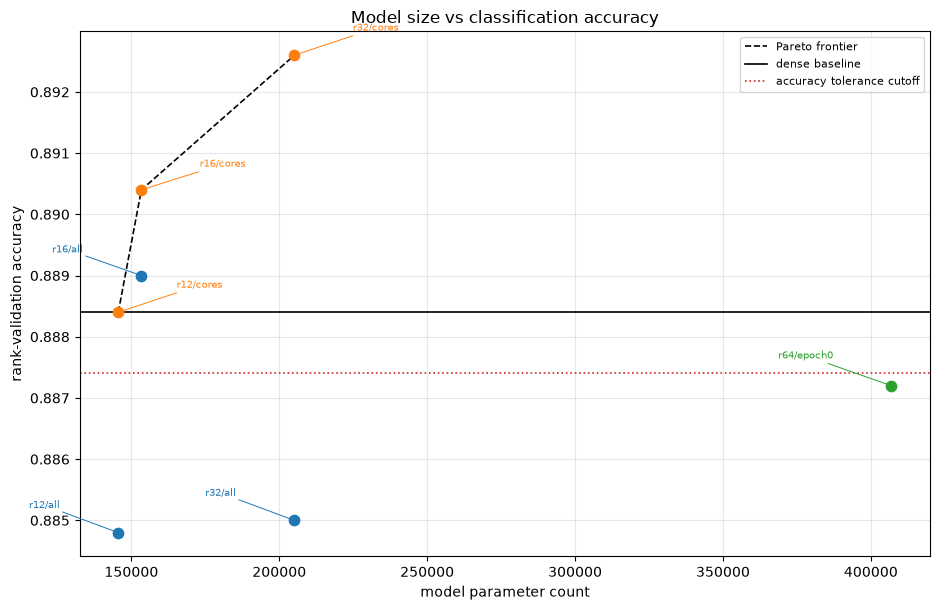

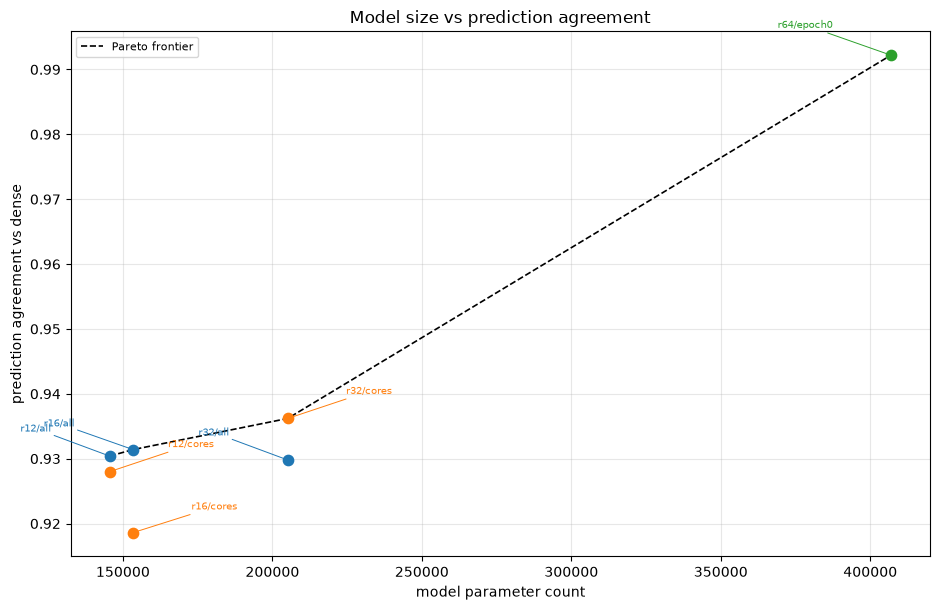

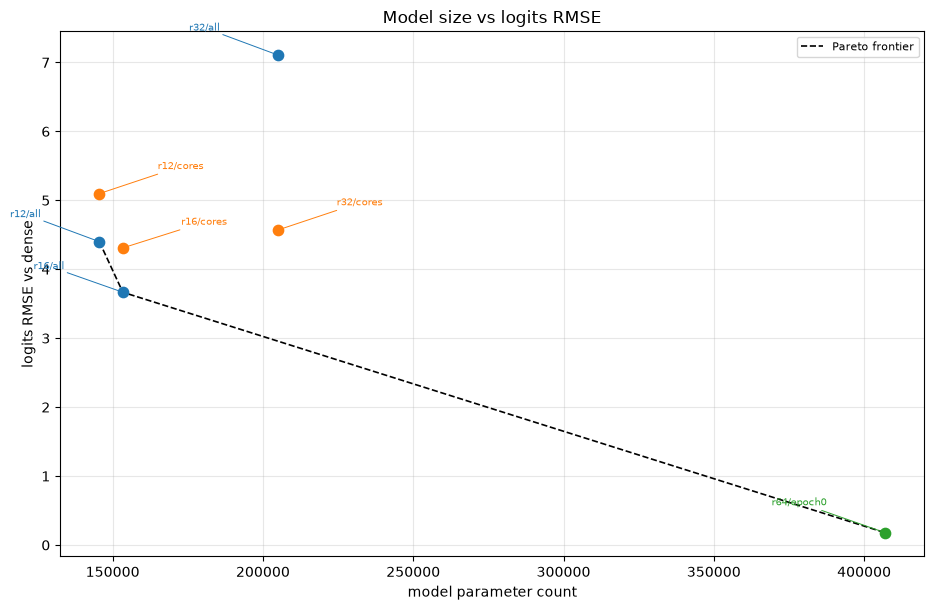

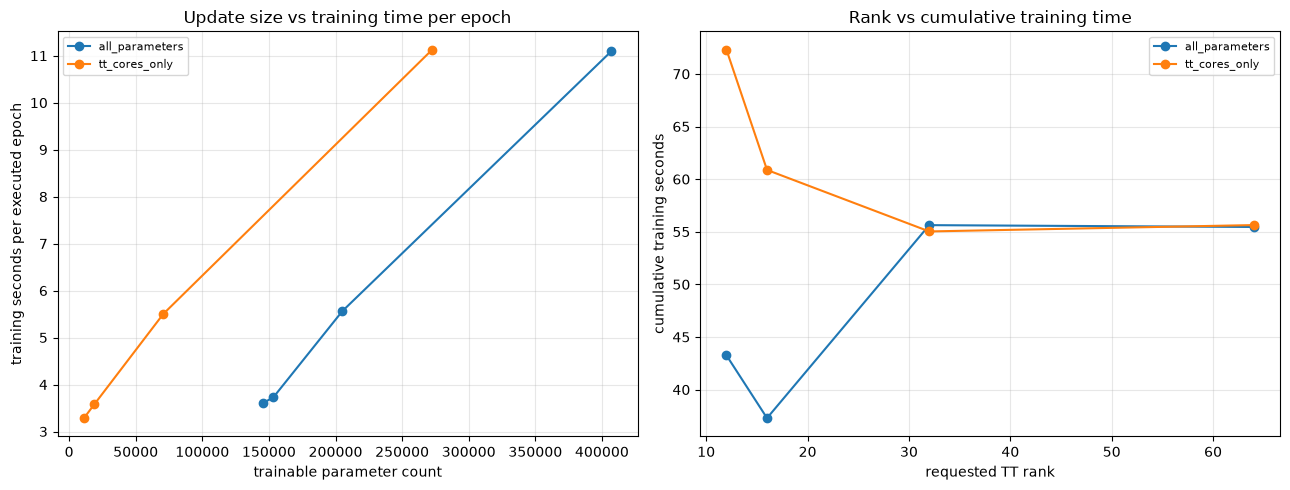

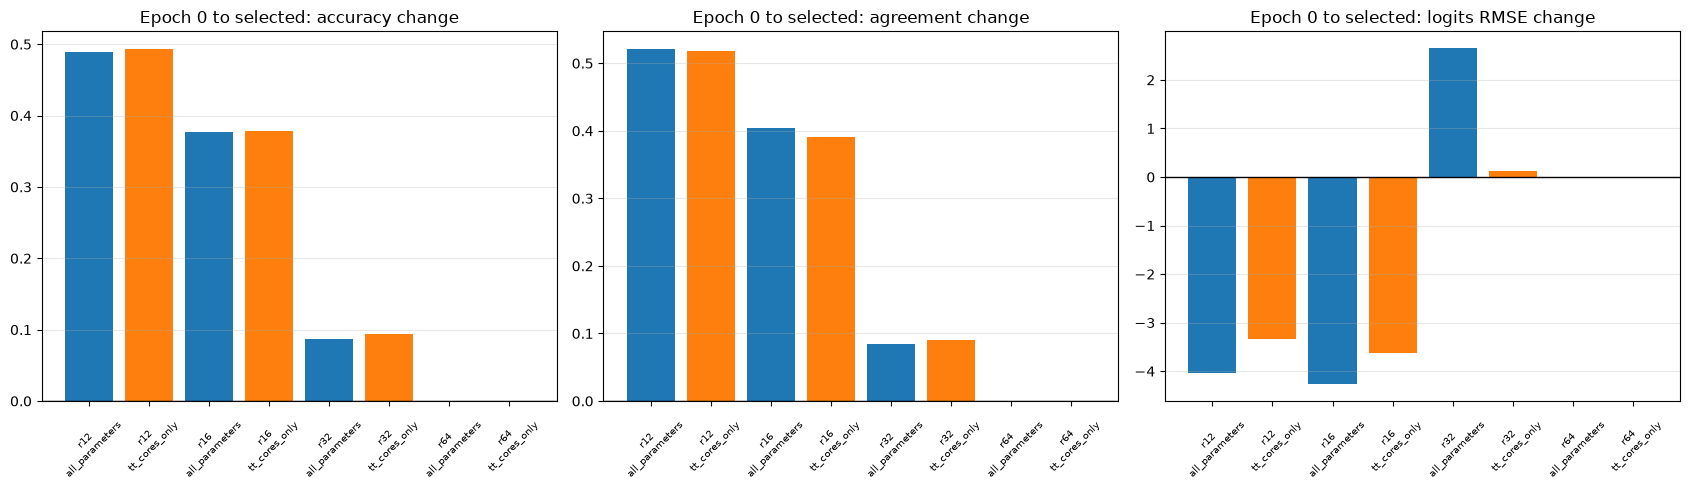

In [30]:
scope_colors = {
    "all_parameters": "tab:blue",
    "tt_cores_only": "tab:orange",
    "common_epoch0": "tab:green",
}
scope_short_labels = {
    "all_parameters": "all",
    "tt_cores_only": "cores",
    "common_epoch0": "epoch0",
}
# 同一xに複数点があるとき、ラベルを扇状に逃がす
LABEL_OFFSETS = [
    (-42, 16),
    (42, 16),
    (-42, -22),
    (42, -22),
    (-54, 34),
    (54, -38),
    (0, 44),
]


def plot_model_tradeoff(
    ax: Axes,
    candidates: pd.DataFrame,
    pareto: pd.DataFrame,
    metric_column: str,
    ylabel: str,
    title: str,
) -> None:
    """モデルparameter数と1つの評価指標を描画する。

    Args:
        ax: 描画対象のmatplotlib Axes。
        candidates: 全モデル候補を持つDataFrame。
        pareto: 対象指標のPareto候補を持つDataFrame。
        metric_column: 縦軸に使う列名。
        ylabel: 縦軸ラベル。
        title: Figureタイトル。

    Returns:
        なし。渡されたAxesを更新する。
    """
    # 同じmodel_parameters内で連番を振り、全点に必ず注釈を付ける
    # 列名は itertuples 向けに先頭アンダースコアを付けない
    labeled = candidates.copy()
    labeled["label_slot"] = (
        labeled.groupby("model_parameters", sort=False).cumcount()
    )

    for row in labeled.itertuples(index=False):
        scope = str(row.update_scope)
        color = scope_colors[scope]
        y_value = float(getattr(row, metric_column))
        ax.scatter(row.model_parameters, y_value, color=color, s=55, zorder=3)

        offset_x, offset_y = LABEL_OFFSETS[
            int(row.label_slot) % len(LABEL_OFFSETS)
        ]
        # rankでもう一段ずらし、別xのラベル同士の衝突も減らす
        offset_y += (int(row.requested_rank) % 5) - 2
        short = scope_short_labels.get(scope, scope)
        ax.annotate(
            f"r{int(row.requested_rank)}/{short}",
            (row.model_parameters, y_value),
            xytext=(offset_x, offset_y),
            textcoords="offset points",
            fontsize=7,
            color=color,
            ha="right" if offset_x < 0 else "left",
            va="bottom" if offset_y >= 0 else "top",
            arrowprops=dict(
                arrowstyle="-",
                color=color,
                lw=0.7,
                shrinkA=0,
                shrinkB=3,
            ),
            clip_on=False,
            zorder=4,
        )
    pareto_sorted = pareto.sort_values("model_parameters")
    ax.plot(
        pareto_sorted["model_parameters"],
        pareto_sorted[metric_column],
        color="black", linestyle="--", linewidth=1.2,
        label="Pareto frontier",
    )
    ax.set_xlabel("model parameter count")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)


fig_accuracy_tradeoff, ax_accuracy = plt.subplots(figsize=(9.5, 6.2))
plot_model_tradeoff(
    ax_accuracy, df_model_candidates, df_pareto_accuracy,
    "rank_validation_accuracy", "rank-validation accuracy",
    "Model size vs classification accuracy",
)
ax_accuracy.axhline(
    dense_rank_validation_accuracy, color="black", linewidth=1.2,
    label="dense baseline",
)
ax_accuracy.axhline(
    accuracy_cutoff, color="tab:red", linestyle=":", linewidth=1.2,
    label="accuracy tolerance cutoff",
)
ax_accuracy.legend(fontsize=8, loc="best")
fig_accuracy_tradeoff.tight_layout()
plt.show()

fig_agreement_tradeoff, ax_agreement = plt.subplots(figsize=(9.5, 6.2))
plot_model_tradeoff(
    ax_agreement, df_model_candidates, df_pareto_agreement,
    "prediction_agreement", "prediction agreement vs dense",
    "Model size vs prediction agreement",
)
fig_agreement_tradeoff.tight_layout()
plt.show()

fig_rmse_tradeoff, ax_rmse = plt.subplots(figsize=(9.5, 6.2))
plot_model_tradeoff(
    ax_rmse, df_model_candidates, df_pareto_logits_rmse,
    "logits_rmse", "logits RMSE vs dense",
    "Model size vs logits RMSE",
)
fig_rmse_tradeoff.tight_layout()
plt.show()

fig_training_cost, axes_cost = plt.subplots(1, 2, figsize=(13, 5.0))
for scope, color in scope_colors.items():
    if scope == "common_epoch0":
        continue
    frame = df_integrated_trials.loc[
        df_integrated_trials["update_scope"] == scope
    ].sort_values("requested_rank")
    axes_cost[0].plot(
        frame["trainable_parameters"],
        frame["training_seconds_per_epoch"],
        marker="o", color=color, label=scope,
    )
    axes_cost[1].plot(
        frame["requested_rank"],
        frame["cumulative_training_seconds"],
        marker="o", color=color, label=scope,
    )
axes_cost[0].set_xlabel("trainable parameter count")
axes_cost[0].set_ylabel("training seconds per executed epoch")
axes_cost[0].set_title("Update size vs training time per epoch")
axes_cost[1].set_xlabel("requested TT rank")
axes_cost[1].set_ylabel("cumulative training seconds")
axes_cost[1].set_title("Rank vs cumulative training time")
for ax in axes_cost:
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
fig_training_cost.tight_layout()
plt.show()

change_columns = [
    ("accuracy_change_from_epoch0", "accuracy change"),
    ("agreement_change_from_epoch0", "agreement change"),
    ("logits_rmse_change_from_epoch0", "logits RMSE change"),
]
plot_labels = [
    f"r{row.requested_rank}\n{row.update_scope}"
    for row in df_integrated_trials.itertuples(index=False)
]
fig_epoch0_changes, axes_change = plt.subplots(1, 3, figsize=(17, 5.0))
for ax, (column, title) in zip(axes_change, change_columns):
    colors = [scope_colors[scope] for scope in df_integrated_trials["update_scope"]]
    ax.bar(plot_labels, df_integrated_trials[column], color=colors)
    ax.axhline(0.0, color="black", linewidth=1.0)
    ax.set_title(f"Epoch 0 to selected: {title}")
    ax.tick_params(axis="x", rotation=45, labelsize=7)
    ax.grid(True, axis="y", alpha=0.3)
fig_epoch0_changes.tight_layout()
plt.show()

## 7. このNotebookで言えること／言わないこと

暫定候補は、保存済みの単一seed結果へ既存のaccuracy toleranceを適用した結果です。testに対する最終性能、複数seedでの安定性、推論latency、MACs、一般的に最良なTT-rankを意味しません。

入力の役割は、性能・時間がNotebook 13・14のCSV、比較条件とdense基準値がNotebook 13・14本体、rank 64の完全一致が保存済みcheckpointです。Notebook 08のCSVには依存しません。

また、cores-onlyは学習対象parameter数を減らしますが、同rankの推論モデル総parameter数を減らしません。学習対象数の削減が時間短縮へ直結したかどうかは、停止epochと秒／epochを分けて読みます。

Notebook 16以降の実験は、この統合結果を確認してから選びます。

In [31]:
# Notebook 15専用の表と図だけを保存する。
if SAVE_RESULTS:
    results_dir.mkdir(parents=True, exist_ok=True)

    csv_outputs = {
        "integration_provenance.csv": df_integration_provenance,
        "dense_baseline_reference.csv": df_dense_baseline_reference,
        "integrated_trial_comparison.csv": df_integrated_trials,
        "integrated_epoch0.csv": df_integrated_epoch0,
        "epoch0_pair_verification.csv": df_epoch0_pair_verification,
        "checkpoint_equivalence.csv": df_checkpoint_equivalence,
        "integrated_model_candidates.csv": df_model_candidates,
        "pareto_accuracy.csv": df_pareto_accuracy,
        "pareto_agreement.csv": df_pareto_agreement,
        "pareto_logits_rmse.csv": df_pareto_logits_rmse,
        "accuracy_tolerance_candidates.csv": (
            df_accuracy_tolerance_candidates
        ),
        "provisional_min_parameter_candidates.csv": (
            df_provisional_candidates
        ),
        "accuracy_knee_auxiliary.csv": df_accuracy_knee,
        "selection_rationale.csv": df_selection_rationale,
    }
    for filename, frame in csv_outputs.items():
        frame.to_csv(results_dir / filename, index=False)

    figure_outputs = {
        "model_parameters_vs_accuracy.png": fig_accuracy_tradeoff,
        "model_parameters_vs_agreement.png": fig_agreement_tradeoff,
        "model_parameters_vs_logits_rmse.png": fig_rmse_tradeoff,
        "training_cost_comparison.png": fig_training_cost,
        "epoch0_to_selected_changes.png": fig_epoch0_changes,
    }
    for filename, figure in figure_outputs.items():
        figure.savefig(results_dir / filename, dpi=150, bbox_inches="tight")

    expected_paths = [
        *(results_dir / name for name in csv_outputs),
        *(results_dir / name for name in figure_outputs),
    ]
    for output_path in expected_paths:
        assert output_path.is_file(), output_path

    print(f"saved {len(expected_paths)} artifacts to: {results_dir}")
else:
    print("SAVE_RESULTS=False: 結果は保存していません。")

saved 19 artifacts to: D:\dev\nn-compression-svd-dmrg\results\30_tt_mps\10_fashion_mnist_mlp\15_integrated_tt_rank_update_scope_tradeoff
